In [ ]:
# !git clone --recursive https://github.com/microsoft/BitNet.git
# %cd BitNet
# !pip install -q -r requirements.txt
# %cd gpu
# !pip install -q -r requirements.txt
# !pip install -q --upgrade torch torchvision torchaudio

!pip install bitblas -qq


Cloning into 'BitNet'...
remote: Enumerating objects: 432, done.
remote: Total 432 (delta 0), reused 0 (delta 0), pack-reused 432 (from 1)
Receiving objects: 100% (432/432), 8.12 MiB | 13.60 MiB/s, done.
Resolving deltas: 100% (196/196), done.
Submodule '3rdparty/llama.cpp' (https://github.com/Eddie-Wang1120/llama.cpp.git) registered for path '3rdparty/llama.cpp'
Cloning into '/content/BitNet/3rdparty/llama.cpp'...
remote: Enumerating objects: 25639, done.        
remote: Total 25639 (delta 0), reused 0 (delta 0), pack-reused 25639 (from 1)        
Receiving objects: 100% (25639/25639), 59.71 MiB | 16.18 MiB/s, done.
Resolving deltas: 100% (18203/18203), done.
Submodule path '3rdparty/llama.cpp': checked out '1f86f058de0c3f4098dedae2ae8653c335c868a1'
Submodule 'kompute' (https://github.com/nomic-ai/kompute.git) registered for path '3rdparty/llama.cpp/ggml/src/kompute'
Cloning into '/content/BitNet/3rdparty/llama.cpp/ggml/src/kompute'...
remote: Enumerating objects: 9122, done.        


In [ ]:
##### RESTART Runtime Here #####

In [ ]:
import os
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"using {device} device")

using cuda device


In [ ]:
import torchvision
import torchvision.transforms as transforms

BATCH_SIZE = 128


from datasets import load_dataset
raw = load_dataset("cifar10")

mean = torch.tensor([0.4914, 0.4822, 0.4465])
std = torch.tensor([0.2470, 0.2435, 0.2616])


# # define transforms and augmentations
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

transform_val_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean,std=std)
])

# apply transforms
def apply_train_transform(examples):
    examples["img"] = [transform_train(img) for img in examples["img"]]
    return examples

def apply_val_test_transform(examples):
    examples["img"] = [transform_val_test(img) for img in examples["img"]]
    return examples

train_val = raw["train"].with_transform(apply_train_transform)
test_dataset = raw["test"].with_transform(apply_val_test_transform)

# split train into train and validation
train_dataset, validation_dataset = torch.utils.data.random_split(
    train_val, [40000, 10000],
    generator=torch.Generator().manual_seed(993)
)


print(f"\nTraining samples: {len(train_dataset)}")
print(f"Validation samples: {len(validation_dataset)}")
print(f"Test samples: {len(test_dataset)}")


def collate_fn(batch):
    images = torch.stack([item["img"] for item in batch])
    labels = torch.tensor([item["label"] for item in batch])
    return images, labels

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers = os.cpu_count(),
    persistent_workers=True,
    pin_memory=True,
    collate_fn=collate_fn
)

val_loader = torch.utils.data.DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers = os.cpu_count(),
    persistent_workers=True,
    pin_memory=True,
    collate_fn=collate_fn
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers = os.cpu_count(),
    persistent_workers=True,
    pin_memory=True,
    collate_fn=collate_fn
)


Training samples: 40000
Validation samples: 10000
Test samples: 10000


In [ ]:
import torch.nn as nn

def RMSNorm(x, eps=1e-5):
    return x / torch.sqrt(x.pow(2).mean(dim=-1, keepdim=True) + eps)

def activation_quant(x):
  scale = 127.0 / x.abs().max(dim=-1, keepdim=True).values.clamp_(min=1e-5)
  y = (x * scale).round().clamp_(-128,127) / scale
  return y

def weight_quant(w):
  scale = 1.0 / w.abs().mean().clamp_(min=1e-5)
  u = (w * scale).round().clamp_(-1,1) / scale
  return u



class BitLinear(nn.Linear):
  def forward(self,x):
    w = self.weight
    x_norm = RMSNorm(x)
    x_quant = x_norm + (activation_quant(x_norm) - x_norm).detach()
    w_quant = w + (weight_quant(w) - w).detach()
    y = F.linear(x_quant,w_quant)
    return y

In [ ]:
import bitblas

print("Compiling BitBLAS operators...")
bitblas_matmuls = {}
unique_shapes = [(32, 128)]
m_values = [128] # must match batch size

for (n, k) in unique_shapes:
    bitblas_matmuls[(n, k)] = {}
    for m in m_values:
        print(f"Compiling M={m}, N={n}, K={k}...")
        config = bitblas.MatmulConfig(
            M=m, N=n, K=k,
            A_dtype="int8", W_dtype="int2",
            accum_dtype="int32", out_dtype="float32",
        )
        bitblas_matmuls[(n, k)][m] = bitblas.Matmul(config=config)
        print(f"  Done")

print("All operators compiled successfully")

# reference correctness checks
print("\nRunning reference tests...")
for (n, k) in unique_shapes:
    for m in m_values:
        test = bitblas_matmuls[(n, k)][m]
        inp = torch.randint(-128, 127, (m, k), dtype=torch.int8).cuda()
        w = torch.randint(-1, 2, (n, k), dtype=torch.int8).cuda()
        out = test(inp.contiguous(), test.transform_weight(w).contiguous())
        ref = torch.matmul(inp.float(), w.float().t())
        max_diff = (out.float() - ref.float()).abs().max()
        try:
            torch.testing.assert_close(out.float(), ref.float(), rtol=1e-2, atol=1.0)
            print(f"M={m}, N={n}, K={k}: ✅ max_diff={max_diff:.4f}")
        except AssertionError:
            print(f"M={m}, N={n}, K={k}: ❌ max_diff={max_diff:.4f}")

Compiling BitBLAS operators...
Compiling M=128, N=32, K=128...
  Done
All operators compiled successfully

Running reference tests...
M=128, N=32, K=128: ✅ max_diff=0.0000


In [ ]:
class BitLinearKernel(nn.Module):
    def __init__(self, in_features: int, out_features: int, bias: bool = False):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.weight = torch.nn.Parameter(torch.zeros(out_features, in_features//4, dtype=torch.int8), requires_grad=False)
        self.weight_scale = torch.nn.Parameter(torch.ones(1, dtype=torch.float32), requires_grad=False)

    def quant_input(self, input):
        s = 127 / input.abs().max(dim=-1, keepdim=True).values.clamp(min=1e-5)
        return (input * s).round().clamp(-128, 127).to(torch.int8), s



    def forward(self, input):
        original_shape = input.shape
        if input.dim() == 3:
            input = input.reshape(-1, input.shape[-1])

        input, s = self.quant_input(input)
        M = input.shape[0]

        shape_key = (self.out_features, self.in_features)

        # only useful if compiling multiple values of M
        if M in bitblas_matmuls[shape_key]:
            # exact match
            out = bitblas_matmuls[shape_key][M](input.contiguous(), self.weight.contiguous())
        else:
            # find next larger M
            available_ms = [m for m in bitblas_matmuls[shape_key].keys() if m >= M]
            if available_ms:
                next_m = min(available_ms)
                pad_size = next_m - M
                input_padded = torch.cat([input, input[:pad_size]], dim=0)
                out = bitblas_matmuls[shape_key][next_m](input_padded.contiguous(), self.weight.contiguous())
                out = out[:M]
            else:
                # fallback to largest available M with padding
                largest_m = max(bitblas_matmuls[shape_key].keys())
                # this shouldn't happen if M values are chosen correctly
                raise ValueError(f"No suitable M found for M={M}, available: {list(bitblas_matmuls[shape_key].keys())}")

        out = out.float() * self.weight_scale / s
        return out.reshape(*original_shape[:-1], self.out_features)



In [ ]:

import torch.nn.functional as F
import torchvision.models as models
import inspect
import types



bitlinear_model = models.resnet18(weights=None)

bitlinear_model.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1, bias=False)
bitlinear_model.bn1 = nn.BatchNorm2d(16)
bitlinear_model.maxpool = nn.Identity()

bitlinear_model.layer1 = nn.Sequential(
    models.resnet.BasicBlock(16, 16),
    models.resnet.BasicBlock(16, 16),
)
bitlinear_model.layer2 = nn.Sequential(
    models.resnet.BasicBlock(16, 32, stride=2, downsample=nn.Sequential(
        nn.Conv2d(16, 32, kernel_size=1, stride=2, bias=False),
        nn.BatchNorm2d(32),
    )),
    models.resnet.BasicBlock(32, 32),
)
bitlinear_model.layer3 = nn.Sequential(
    models.resnet.BasicBlock(32, 64, stride=2, downsample=nn.Sequential(
        nn.Conv2d(32, 64, kernel_size=1, stride=2, bias=False),
        nn.BatchNorm2d(64),
    )),
    models.resnet.BasicBlock(64, 64),
)

# Remove layer4, fix output layer
bitlinear_model.layer4 = nn.Identity()

bitlinear_model.fc = BitLinear(128,32, bias=False) # applied padding here


def new_forward(self,x):
  x = self.conv1(x)
  x = self.bn1(x)
  x = self.relu(x)
  x = self.maxpool(x)

  x = self.layer1(x)
  x = self.layer2(x)
  x = self.layer3(x)
  x = self.layer4(x)

  x = self.avgpool(x)
  x = torch.flatten(x, 1)
  x = torch.nn.functional.pad(x, (0, 64))  # pad 64 -> 128
  x = self.fc(x)

  return x[:, :10]

  # Note: we have 32 neurons in the output layer due to kernel logic restrictions. Here, we ignore the last 22 neurons.
  # The loss function never sees the final 22 neurons, which means they get no gradient and no weight updates.
  # Their weights never change from whatever they were initialized to, and their outputs are ignored by the slice.

bitlinear_model.forward = types.MethodType(new_forward, bitlinear_model)




In [ ]:
# Baseline model
baseline_model = models.resnet18(weights=None)

baseline_model.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1, bias=False)
baseline_model.bn1 = nn.BatchNorm2d(16)
baseline_model.maxpool = nn.Identity()

baseline_model.layer1 = nn.Sequential(
    models.resnet.BasicBlock(16, 16),
    models.resnet.BasicBlock(16, 16),
)
baseline_model.layer2 = nn.Sequential(
    models.resnet.BasicBlock(16, 32, stride=2, downsample=nn.Sequential(
        nn.Conv2d(16, 32, kernel_size=1, stride=2, bias=False),
        nn.BatchNorm2d(32),
    )),
    models.resnet.BasicBlock(32, 32),
)
baseline_model.layer3 = nn.Sequential(
    models.resnet.BasicBlock(32, 64, stride=2, downsample=nn.Sequential(
        nn.Conv2d(32, 64, kernel_size=1, stride=2, bias=False),
        nn.BatchNorm2d(64),
    )),
    models.resnet.BasicBlock(64, 64),
)

baseline_model.layer4 = nn.Identity()
baseline_model.fc = nn.Linear(128, 32, bias=False)  # same padding
baseline_model.forward = types.MethodType(new_forward, baseline_model)

In [ ]:
kernel_model = models.resnet18(weights=None)


kernel_model.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1, bias=False)
kernel_model.bn1 = nn.BatchNorm2d(16)
kernel_model.maxpool = nn.Identity()


kernel_model.layer1 = nn.Sequential(
    models.resnet.BasicBlock(16, 16),
    models.resnet.BasicBlock(16, 16),
)
kernel_model.layer2 = nn.Sequential(
    models.resnet.BasicBlock(16, 32, stride=2, downsample=nn.Sequential(
        nn.Conv2d(16, 32, kernel_size=1, stride=2, bias=False),
        nn.BatchNorm2d(32),
    )),
    models.resnet.BasicBlock(32, 32),
)
kernel_model.layer3 = nn.Sequential(
    models.resnet.BasicBlock(32, 64, stride=2, downsample=nn.Sequential(
        nn.Conv2d(32, 64, kernel_size=1, stride=2, bias=False),
        nn.BatchNorm2d(64),
    )),
    models.resnet.BasicBlock(64, 64),
)

# Remove layer4, fix output layer
kernel_model.layer4 = nn.Identity()
kernel_model.fc = BitLinearKernel(128,32, bias=False)



def new_forward(self,x):
  x = self.conv1(x)
  x = self.bn1(x)
  x = self.relu(x)
  x = self.maxpool(x)

  x = self.layer1(x)
  x = self.layer2(x)
  x = self.layer3(x)
  x = self.layer4(x)

  x = self.avgpool(x)
  x = torch.flatten(x, 1)
  x = torch.nn.functional.pad(x, (0, 64))  # pad 64 -> 128
  x = self.fc(x)

  return x[:, :10]

  # Note: we have 32 neurons in the output layer due to kernel logic restrictions. Here, we ignore the last 22 neurons.
  # The loss function never sees the final 22 neurons, which means they get no gradient and no weight updates.
  # Their weights never change from whatever they were initialized to, and their outputs are ignored by the slice.

kernel_model.forward = types.MethodType(new_forward, kernel_model)

In [ ]:
import random

def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [ ]:
# Train the baseline model

from tqdm import tqdm
import time
import numpy as np

NUM_EPOCHS = 182
LEARNING_RATE = .1
NUM_RUNS = 3

def init_weights(m):
    if isinstance(m, nn.Conv2d):
        nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.constant_(m.weight, 1)
        nn.init.constant_(m.bias, 0)



run_times_baseline = []
run_final_accs_baseline = []
run_epochs_to_threshold_baseline = []
all_histories_baseline = []

for run in range(NUM_RUNS):
    set_seed(run)

    print(f"\n{'='*40}")
    print(f"Run {run+1}/{NUM_RUNS}")
    print(f"{'='*40}")

    model = baseline_model.to(device)
    model.apply(init_weights)
    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE,momentum=.9,weight_decay=.0001)
    scheduler=torch.optim.lr_scheduler.MultiStepLR(optimizer,milestones=[32000, 48000],gamma=.1)

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    torch.cuda.synchronize()
    start = time.time()

    for i in range(NUM_EPOCHS):
        # Training Phase
        model.train()
        train_loss = 0
        train_correct_predictions = 0
        train_total = 0

        for batch, labels in tqdm(train_loader, desc=f'Epoch {i + 1}/{NUM_EPOCHS} Training'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = model(batch)
            optimizer.zero_grad()

            loss = loss_fn(output, labels)
            train_loss += loss.detach()

            loss.backward()
            optimizer.step()

            predictions = torch.argmax(output, dim=1)
            train_correct_predictions += (predictions == labels).sum()
            train_total += len(labels)

            scheduler.step()

        train_loss = train_loss.cpu().item() / len(train_loader)
        train_acc = train_correct_predictions.cpu().item() / train_total

        # Validation Phase
        model.eval()
        val_loss = 0
        val_correct_predictions = 0
        val_total = 0

        with torch.no_grad():
            for batch, labels in tqdm(val_loader, desc=f'Epoch {i + 1}/{NUM_EPOCHS} Validation'):
                batch = batch.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                output = model(batch)
                loss = loss_fn(output, labels)

                val_loss += loss.detach()

                predictions = torch.argmax(output, dim=1)
                val_correct_predictions += (predictions == labels).sum()
                val_total += len(labels)

        val_loss = val_loss.cpu().item() / len(val_loader)
        val_acc = val_correct_predictions.cpu().item() / val_total

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

    torch.cuda.synchronize()
    end = time.time()

    run_times_baseline.append(end - start)
    run_final_accs_baseline.append(history['val_acc'][-1])
    all_histories_baseline.append(history)

    # 90% threshold
    final_acc = history['val_acc'][-1]
    threshold = 0.9 * final_acc
    epochs_to_threshold = NUM_EPOCHS
    for epoch, acc in enumerate(history['val_acc']):
        if acc >= threshold:
            epochs_to_threshold = epoch + 1
            break
    run_epochs_to_threshold_baseline.append(epochs_to_threshold)

    print(f"\nRun {run+1} results:")
    print(f"  Time: {run_times_baseline[-1]:.2f}s")
    print(f"  Final Validation accuracy: {run_final_accs_baseline[-1]:.4f}")
    print(f"  Epochs to 90% threshold: {epochs_to_threshold}")

    torch.save(model.state_dict(), f'/content/baseline_run{run}.pth')

print(f"\n{'='*40}")
print(f"BASELINE TRAINING SUMMARY ({NUM_RUNS} runs)")
print(f"{'='*40}")
print(f"Training time:           {np.mean(run_times_baseline):.2f}s ± {np.std(run_times_baseline):.2f}s")
print(f"Final Validation accuracy:          {np.mean(run_final_accs_baseline):.4f} ± {np.std(run_final_accs_baseline):.4f}")
print(f"Epochs to 90% threshold: {np.mean(run_epochs_to_threshold_baseline):.1f} ± {np.std(run_epochs_to_threshold_baseline):.1f}")


Run 1/3


Epoch 182/182 Validation: 100%|██████████| 79/79 [00:00<00:00, 117.34it/s]



Run 1 results:
  Time: 829.53s
  Final Validation accuracy: 0.9036
  Epochs to 90% threshold: 14

Run 2/3


Epoch 182/182 Validation: 100%|██████████| 79/79 [00:00<00:00, 114.32it/s]



Run 2 results:
  Time: 831.94s
  Final Validation accuracy: 0.8980
  Epochs to 90% threshold: 18

Run 3/3


Epoch 182/182 Validation: 100%|██████████| 79/79 [00:00<00:00, 116.33it/s]


Run 3 results:
  Time: 830.81s
  Final Validation accuracy: 0.8989
  Epochs to 90% threshold: 16

BASELINE TRAINING SUMMARY (3 runs)
Training time:           830.76s ± 0.98s
Final Validation accuracy:          0.9002 ± 0.0025
Epochs to 90% threshold: 16.0 ± 1.6


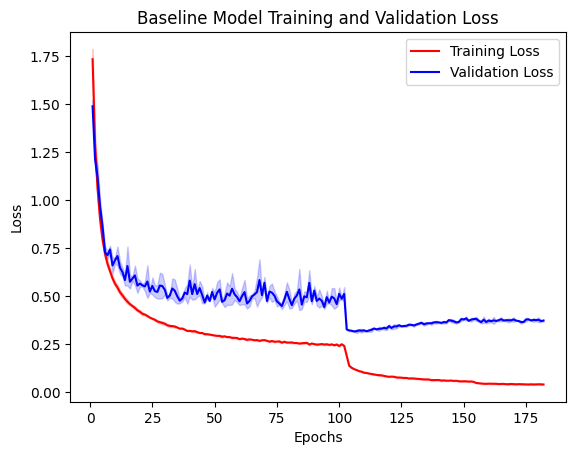

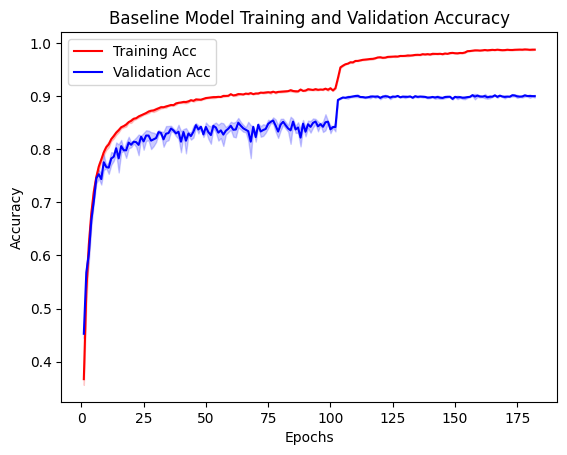

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# collect all histories
all_train_loss = np.array([h['train_loss'] for h in all_histories_baseline])
all_val_loss = np.array([h['val_loss'] for h in all_histories_baseline])
all_train_acc = np.array([h['train_acc'] for h in all_histories_baseline])
all_val_acc = np.array([h['val_acc'] for h in all_histories_baseline])

epochs = np.arange(1, NUM_EPOCHS + 1)

plt.figure()
plt.plot(epochs, all_train_loss.mean(axis=0), label='Training Loss', color='red')
plt.fill_between(epochs,
                 all_train_loss.mean(axis=0) - all_train_loss.std(axis=0),
                 all_train_loss.mean(axis=0) + all_train_loss.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_loss.mean(axis=0), label='Validation Loss', color='blue')
plt.fill_between(epochs,
                 all_val_loss.mean(axis=0) - all_val_loss.std(axis=0),
                 all_val_loss.mean(axis=0) + all_val_loss.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Baseline Model Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig('/content/baseline_loss_plot.pdf',bbox_inches='tight', dpi=300)
plt.show()

plt.figure()
plt.plot(epochs, all_train_acc.mean(axis=0), label='Training Acc', color='red')
plt.fill_between(epochs,
                 all_train_acc.mean(axis=0) - all_train_acc.std(axis=0),
                 all_train_acc.mean(axis=0) + all_train_acc.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_acc.mean(axis=0), label='Validation Acc', color='blue')
plt.fill_between(epochs,
                 all_val_acc.mean(axis=0) - all_val_acc.std(axis=0),
                 all_val_acc.mean(axis=0) + all_val_acc.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Baseline Model Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig('/content/baseline_acc_plot.pdf',bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil
shutil.copy('/content/baseline_loss_plot.pdf', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/CNN_bitblas/cnn_bitblas_baseline_loss_plot.pdf')
shutil.copy('/content/baseline_acc_plot.pdf', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/CNN_bitblas/cnn_bitblas_baseline_accuracy_plot.pdf')

'/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/CNN_bitblas/cnn_bitblas_baseline_accuracy_plot.pdf'

In [ ]:
# train the bitlinear model

from tqdm import tqdm
import time
import numpy as np


run_times = []
run_final_accs = []
run_epochs_to_threshold = []
all_histories = []

for run in range(NUM_RUNS):
    set_seed(run)

    print(f"\n{'='*40}")
    print(f"Run {run+1}/{NUM_RUNS}")
    print(f"{'='*40}")

    model = bitlinear_model.to(device)
    model.apply(init_weights)
    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=0.0001)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[32000, 48000], gamma=0.1)

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    torch.cuda.synchronize()
    start = time.time()

    for i in range(NUM_EPOCHS):
        # Training Phase
        model.train()
        train_loss = 0
        train_correct_predictions = 0
        train_total = 0

        for batch, labels in tqdm(train_loader, desc=f'Epoch {i + 1}/{NUM_EPOCHS} Training'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = model(batch)
            optimizer.zero_grad()

            loss = loss_fn(output, labels)
            train_loss += loss.detach()

            loss.backward()
            optimizer.step()

            predictions = torch.argmax(output, dim=1)
            train_correct_predictions += (predictions == labels).sum()
            train_total += len(labels)

            scheduler.step()

        train_loss = train_loss.cpu().item() / len(train_loader)
        train_acc = train_correct_predictions.cpu().item() / train_total

        # Validation Phase
        model.eval()
        val_loss = 0
        val_correct_predictions = 0
        val_total = 0

        with torch.no_grad():
            for batch, labels in tqdm(val_loader, desc=f'Epoch {i + 1}/{NUM_EPOCHS} Validation'):
                batch = batch.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                output = model(batch)
                loss = loss_fn(output, labels)

                val_loss += loss.detach()

                predictions = torch.argmax(output, dim=1)
                val_correct_predictions += (predictions == labels).sum()
                val_total += len(labels)

        val_loss = val_loss.cpu().item() / len(val_loader)
        val_acc = val_correct_predictions.cpu().item() / val_total

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

    torch.cuda.synchronize()
    end = time.time()

    run_times.append(end - start)
    run_final_accs.append(history['val_acc'][-1])
    all_histories.append(history)

    # 90% threshold
    final_acc = history['val_acc'][-1]
    threshold = 0.9 * final_acc
    epochs_to_threshold = NUM_EPOCHS
    for epoch, acc in enumerate(history['val_acc']):
        if acc >= threshold:
            epochs_to_threshold = epoch + 1
            break
    run_epochs_to_threshold.append(epochs_to_threshold)

    print(f"\nRun {run+1} results:")
    print(f"  Time: {run_times[-1]:.2f}s")
    print(f"  Final validation accuracy: {run_final_accs[-1]:.4f}")
    print(f"  Epochs to 90% threshold: {epochs_to_threshold}")

    torch.save(model.state_dict(), f'/content/bitlinear_run{run}.pth')

print(f"\n{'='*40}")
print(f"BITLINEAR TRAINING SUMMARY ({NUM_RUNS} runs)")
print(f"{'='*40}")
print(f"Training time:           {np.mean(run_times):.2f}s ± {np.std(run_times):.2f}s")
print(f"Final validation accuracy:          {np.mean(run_final_accs):.4f} ± {np.std(run_final_accs):.4f}")
print(f"Epochs to 90% threshold: {np.mean(run_epochs_to_threshold):.1f} ± {np.std(run_epochs_to_threshold):.1f}")


Run 1/3


Epoch 182/182 Validation: 100%|██████████| 79/79 [00:00<00:00, 104.70it/s]



Run 1 results:
  Time: 893.94s
  Final validation accuracy: 0.8996
  Epochs to 90% threshold: 20

Run 2/3


Epoch 182/182 Validation: 100%|██████████| 79/79 [00:00<00:00, 111.62it/s]



Run 2 results:
  Time: 894.80s
  Final validation accuracy: 0.8974
  Epochs to 90% threshold: 18

Run 3/3


Epoch 182/182 Validation: 100%|██████████| 79/79 [00:00<00:00, 107.07it/s]


Run 3 results:
  Time: 895.06s
  Final validation accuracy: 0.8973
  Epochs to 90% threshold: 14

BITLINEAR TRAINING SUMMARY (3 runs)
Training time:           894.60s ± 0.48s
Final validation accuracy:          0.8981 ± 0.0011
Epochs to 90% threshold: 17.3 ± 2.5


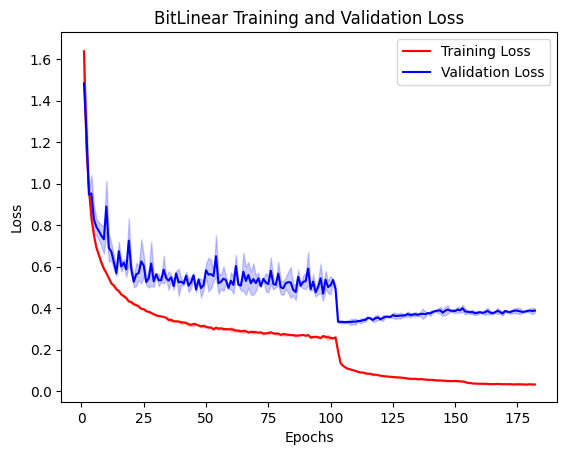

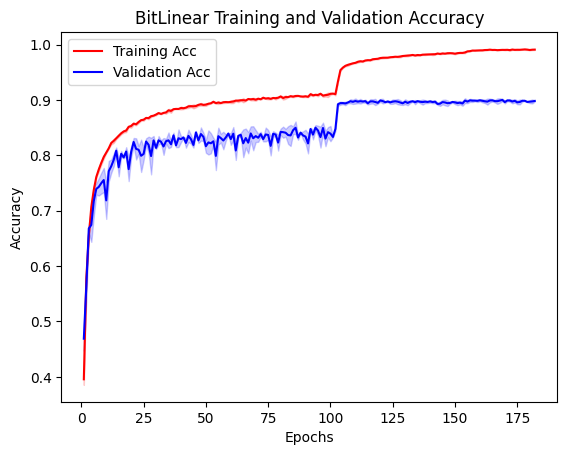

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# collect all histories
all_train_loss = np.array([h['train_loss'] for h in all_histories])
all_val_loss = np.array([h['val_loss'] for h in all_histories])
all_train_acc = np.array([h['train_acc'] for h in all_histories])
all_val_acc = np.array([h['val_acc'] for h in all_histories])

epochs = np.arange(1, NUM_EPOCHS + 1)

plt.figure()
plt.plot(epochs, all_train_loss.mean(axis=0), label='Training Loss', color='red')
plt.fill_between(epochs,
                 all_train_loss.mean(axis=0) - all_train_loss.std(axis=0),
                 all_train_loss.mean(axis=0) + all_train_loss.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_loss.mean(axis=0), label='Validation Loss', color='blue')
plt.fill_between(epochs,
                 all_val_loss.mean(axis=0) - all_val_loss.std(axis=0),
                 all_val_loss.mean(axis=0) + all_val_loss.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('BitLinear Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig('/content/bitlinear_loss_plot.pdf',bbox_inches='tight', dpi=300)
plt.show()

plt.figure()
plt.plot(epochs, all_train_acc.mean(axis=0), label='Training Acc', color='red')
plt.fill_between(epochs,
                 all_train_acc.mean(axis=0) - all_train_acc.std(axis=0),
                 all_train_acc.mean(axis=0) + all_train_acc.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_acc.mean(axis=0), label='Validation Acc', color='blue')
plt.fill_between(epochs,
                 all_val_acc.mean(axis=0) - all_val_acc.std(axis=0),
                 all_val_acc.mean(axis=0) + all_val_acc.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('BitLinear Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig('/content/bitlinear_acc_plot.pdf',bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
shutil.copy('/content/bitlinear_loss_plot.pdf', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/CNN_bitblas/cnn_bitblas_bitlinear_loss_plot.pdf')
shutil.copy('/content/bitlinear_acc_plot.pdf', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/CNN_bitblas/cnn_bitblas_bitlinear_accuracy_plot.pdf')

'/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/CNN_bitblas/cnn_bitblas_bitlinear_accuracy_plot.pdf'

In [ ]:
def warmup_gpu(model, dataloader, num_batches=5):
    model.eval()
    with torch.no_grad():
        for i, (batch, _) in enumerate(dataloader):
            if i >= num_batches:
                break
            batch = batch.to(device)
            _ = model(batch)
    torch.cuda.synchronize() # ensures that warmup completes before training and timing begins.
    print(f"GPU warmup complete ({num_batches} batches)")

In [ ]:
import numpy as np

NUM_EVAL_RUNS = 3

# baseline evaluation
eval_times_baseline = []
eval_losses_baseline = []
eval_accs_baseline = []
eval_latencies_baseline = []
eval_throughputs_baseline = []

for run in range(NUM_EVAL_RUNS):
    baseline_model.load_state_dict(torch.load(f'/content/baseline_run{run}.pth'))
    baseline_model.to(device).eval()

    if run == 0:
        warmup_gpu(baseline_model, val_loader)

    test_loss = 0
    test_correct_predictions = 0
    test_total = 0

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        for batch, labels in tqdm(test_loader, desc=f'Baseline Testing run {run+1}/{NUM_EVAL_RUNS}'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            output = baseline_model(batch)
            loss = loss_fn(output, labels)
            test_loss += loss.item()
            predictions = torch.argmax(output, dim=1)
            test_correct_predictions += (predictions == labels).sum().item()
            test_total += len(labels)

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    eval_times_baseline.append(run_time)
    eval_losses_baseline.append(test_loss / len(test_loader))
    eval_accs_baseline.append(test_correct_predictions / test_total)
    eval_latencies_baseline.append(run_time / len(test_loader) * 1000)
    eval_throughputs_baseline.append(test_total / run_time)

    print(f"Run {run+1}: Time={run_time:.2f}s, Loss={eval_losses_baseline[-1]:.4f}, Accuracy={eval_accs_baseline[-1]:.4f}, Latency={eval_latencies_baseline[-1]:.2f}ms, Throughput={eval_throughputs_baseline[-1]:.2f} samples/s")

print(f"\n{'='*40}")
print(f"BASELINE INFERENCE SUMMARY ({NUM_EVAL_RUNS} runs)")
print(f"{'='*40}")
print(f"Time:       {np.mean(eval_times_baseline):.2f}s ± {np.std(eval_times_baseline):.2f}s")
print(f"Loss:       {np.mean(eval_losses_baseline):.4f} ± {np.std(eval_losses_baseline):.4f}")
print(f"Accuracy:   {np.mean(eval_accs_baseline):.4f} ± {np.std(eval_accs_baseline):.4f}")
print(f"Latency:    {np.mean(eval_latencies_baseline):.2f}ms ± {np.std(eval_latencies_baseline):.2f}ms")
print(f"Throughput: {np.mean(eval_throughputs_baseline):.2f} ± {np.std(eval_throughputs_baseline):.2f} samples/s")

GPU warmup complete (5 batches)


Baseline Testing run 1/3: 100%|██████████| 79/79 [00:00<00:00, 79.15it/s] 


Run 1: Time=1.00s, Loss=0.4328, Accuracy=0.8990, Latency=12.69ms, Throughput=9971.91 samples/s


Baseline Testing run 2/3: 100%|██████████| 79/79 [00:00<00:00, 149.83it/s]


Run 2: Time=0.53s, Loss=0.4211, Accuracy=0.8995, Latency=6.70ms, Throughput=18878.91 samples/s


Baseline Testing run 3/3: 100%|██████████| 79/79 [00:00<00:00, 140.56it/s]

Run 3: Time=0.56s, Loss=0.4146, Accuracy=0.8988, Latency=7.14ms, Throughput=17731.00 samples/s

BASELINE INFERENCE SUMMARY (3 runs)
Time:       0.70s ± 0.22s
Loss:       0.4228 ± 0.0075
Accuracy:   0.8991 ± 0.0003
Latency:    8.85ms ± 2.73ms
Throughput: 15527.27 ± 3956.09 samples/s


In [ ]:
# bitlinear evaluation
eval_times_bitlinear = []
eval_losses_bitlinear = []
eval_accs_bitlinear = []
eval_latencies_bitlinear = []
eval_throughputs_bitlinear = []

for run in range(NUM_EVAL_RUNS):
    bitlinear_model.load_state_dict(torch.load(f'/content/bitlinear_run{run}.pth'))
    bitlinear_model.to(device).eval()

    if run == 0:
        warmup_gpu(bitlinear_model, val_loader)

    test_loss = 0
    test_correct_predictions = 0
    test_total = 0

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        for batch, labels in tqdm(test_loader, desc=f'BitLinear Testing run {run+1}/{NUM_EVAL_RUNS}'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            output = bitlinear_model(batch)
            loss = loss_fn(output, labels)
            test_loss += loss.item()
            predictions = torch.argmax(output, dim=1)
            test_correct_predictions += (predictions == labels).sum().item()
            test_total += len(labels)

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    eval_times_bitlinear.append(run_time)
    eval_losses_bitlinear.append(test_loss / len(test_loader))
    eval_accs_bitlinear.append(test_correct_predictions / test_total)
    eval_latencies_bitlinear.append(run_time / len(test_loader) * 1000)
    eval_throughputs_bitlinear.append(test_total / run_time)

    print(f"Run {run+1}: Time={run_time:.2f}s, Loss={eval_losses_bitlinear[-1]:.4f}, Accuracy={eval_accs_bitlinear[-1]:.4f}, Latency={eval_latencies_bitlinear[-1]:.2f}ms, Throughput={eval_throughputs_bitlinear[-1]:.2f} samples/s")

print(f"\n{'='*40}")
print(f"CNN BITLINEAR INFERENCE SUMMARY ({NUM_EVAL_RUNS} runs)")
print(f"{'='*40}")
print(f"Time:       {np.mean(eval_times_bitlinear):.2f}s ± {np.std(eval_times_bitlinear):.2f}s")
print(f"Loss:       {np.mean(eval_losses_bitlinear):.4f} ± {np.std(eval_losses_bitlinear):.4f}")
print(f"Accuracy:   {np.mean(eval_accs_bitlinear):.4f} ± {np.std(eval_accs_bitlinear):.4f}")
print(f"Latency:    {np.mean(eval_latencies_bitlinear):.2f}ms ± {np.std(eval_latencies_bitlinear):.2f}ms")
print(f"Throughput: {np.mean(eval_throughputs_bitlinear):.2f} ± {np.std(eval_throughputs_bitlinear):.2f} samples/s")

GPU warmup complete (5 batches)


BitLinear Testing run 1/3: 100%|██████████| 79/79 [00:00<00:00, 130.54it/s]


Run 1: Time=0.61s, Loss=0.3612, Accuracy=0.9050, Latency=7.73ms, Throughput=16375.91 samples/s


BitLinear Testing run 2/3: 100%|██████████| 79/79 [00:00<00:00, 138.39it/s]


Run 2: Time=0.57s, Loss=0.3668, Accuracy=0.9023, Latency=7.25ms, Throughput=17458.51 samples/s


BitLinear Testing run 3/3: 100%|██████████| 79/79 [00:00<00:00, 137.88it/s]

Run 3: Time=0.58s, Loss=0.3788, Accuracy=0.9000, Latency=7.28ms, Throughput=17384.31 samples/s

CNN BITLINEAR INFERENCE SUMMARY (3 runs)
Time:       0.59s ± 0.02s
Loss:       0.3689 ± 0.0073
Accuracy:   0.9024 ± 0.0020
Latency:    7.42ms ± 0.22ms
Throughput: 17072.91 ± 493.78 samples/s


In [ ]:
# Quantization

for run in range(NUM_RUNS):
    print(f"Quantizing run {run}...")
    checkpoint = torch.load(f'/content/bitlinear_run{run}.pth', map_location='cpu', mmap=True)
    int2_res = {}

    for key, value in checkpoint.items():
        if 'weight' in key and value.dim() == 2:
            scale = 1.0 / value.abs().mean().clamp(min=1e-5)
            weight_int8 = (value * scale).round().clamp(-1, 1).to(torch.int8)

            n, k = value.shape
            if (n, k) in bitblas_matmuls:
                ref_matmul = next(iter(bitblas_matmuls[(n, k)].values()))
                weight_transformed = ref_matmul.transform_weight(weight_int8.cuda()).cpu()
            else:
                weight_transformed = weight_int8

            int2_res[key] = weight_transformed
            int2_res[key.replace('weight', 'weight_scale')] = torch.tensor([1.0 / scale])
        else:
            int2_res[key] = value.clone()

    torch.save(int2_res, f'/content/quantized_run{run}.pth')
    print(f"  Saved to quantized_run{run}.pth")

print("All runs quantized")


Quantizing run 0...
  Saved to quantized_run0.pth
Quantizing run 1...
  Saved to quantized_run1.pth
Quantizing run 2...
  Saved to quantized_run2.pth
All runs quantized


In [ ]:
# inference kernel eval
eval_times_kernel = []
eval_losses_kernel = []
eval_accs_kernel = []
eval_latencies_kernel = []
eval_throughputs_kernel = []

for run in range(NUM_EVAL_RUNS):
    kernel_model.load_state_dict(torch.load(f'/content/quantized_run{run}.pth'), strict=False)
    kernel_model.to(device).eval()

    if run == 0:
        warmup_gpu(kernel_model, val_loader)

    test_loss = 0
    test_correct_predictions = 0
    test_total = 0

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        for batch, labels in tqdm(test_loader, desc=f'Kernel Testing run {run+1}/{NUM_EVAL_RUNS}'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            output = kernel_model(batch)
            loss = loss_fn(output, labels)
            test_loss += loss.item()
            predictions = torch.argmax(output, dim=1)
            test_correct_predictions += (predictions == labels).sum().item()
            test_total += len(labels)

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    eval_times_kernel.append(run_time)
    eval_losses_kernel.append(test_loss / len(test_loader))
    eval_accs_kernel.append(test_correct_predictions / test_total)
    eval_latencies_kernel.append(run_time / len(test_loader) * 1000)
    eval_throughputs_kernel.append(test_total / run_time)

    print(f"Run {run+1}: Time={run_time:.2f}s, Loss={eval_losses_kernel[-1]:.4f}, Accuracy={eval_accs_kernel[-1]:.4f}, Latency={eval_latencies_kernel[-1]:.2f}ms, Throughput={eval_throughputs_kernel[-1]:.2f} samples/s")

print(f"\n{'='*40}")
print(f"INFERENCE KERNEL SUMMARY ({NUM_EVAL_RUNS} runs)")
print(f"{'='*40}")
print(f"Time:       {np.mean(eval_times_kernel):.2f}s ± {np.std(eval_times_kernel):.2f}s")
print(f"Loss:       {np.mean(eval_losses_kernel):.4f} ± {np.std(eval_losses_kernel):.4f}")
print(f"Accuracy:   {np.mean(eval_accs_kernel):.4f} ± {np.std(eval_accs_kernel):.4f}")
print(f"Latency:    {np.mean(eval_latencies_kernel):.2f}ms ± {np.std(eval_latencies_kernel):.2f}ms")
print(f"Throughput: {np.mean(eval_throughputs_kernel):.2f} ± {np.std(eval_throughputs_kernel):.2f} samples/s")

GPU warmup complete (5 batches)


Kernel Testing run 1/3: 100%|██████████| 79/79 [00:00<00:00, 121.91it/s]


Run 1: Time=0.65s, Loss=1.4618, Accuracy=0.9046, Latency=8.24ms, Throughput=15359.17 samples/s


Kernel Testing run 2/3: 100%|██████████| 79/79 [00:00<00:00, 131.93it/s]


Run 2: Time=0.60s, Loss=1.5036, Accuracy=0.9023, Latency=7.61ms, Throughput=16641.37 samples/s


Kernel Testing run 3/3: 100%|██████████| 79/79 [00:00<00:00, 133.81it/s]

Run 3: Time=0.59s, Loss=1.5215, Accuracy=0.9000, Latency=7.50ms, Throughput=16880.16 samples/s

INFERENCE KERNEL SUMMARY (3 runs)
Time:       0.61s ± 0.03s
Loss:       1.4956 ± 0.0250
Accuracy:   0.9023 ± 0.0019
Latency:    7.78ms ± 0.33ms
Throughput: 16293.57 ± 667.87 samples/s


In [ ]:
shutil.copy('/content/baseline_run0.pth', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/checkpoints/ResNet/bitblas/baseline_run0.pth')
shutil.copy('/content/baseline_run1.pth', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/checkpoints/ResNet/bitblas/baseline_run1.pth')
shutil.copy('/content/baseline_run2.pth', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/checkpoints/ResNet/bitblas/baseline_run2.pth')

shutil.copy('/content/bitlinear_run0.pth', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/checkpoints/ResNet/bitblas/bitlinear_run0.pth')
shutil.copy('/content/bitlinear_run1.pth', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/checkpoints/ResNet/bitblas/bitlinear_run1.pth')
shutil.copy('/content/bitlinear_run2.pth', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/checkpoints/ResNet/bitblas/bitlinear_run2.pth')


'/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/checkpoints/ResNet/bitblas/bitlinear_run2.pth'

In [ ]:
def model_stats(model, filepath):
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    size_mb = os.path.getsize(filepath) / 1024**2

    print(f"Total parameters:     {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")
    print(f"Size on disk:         {size_mb:.2f} MB")

print("Baseline:")
model_stats(baseline_model, '/content/baseline_run0.pth')

print("\nBitLinear (unquantized):")
model_stats(bitlinear_model, '/content/bitlinear_run0.pth')

print("\nInference Kernel (quantized):")
model_stats(kernel_model, '/content/quantized_run0.pth')

Baseline:
Total parameters:     178,704
Trainable parameters: 178,704
Size on disk:         0.72 MB

BitLinear (unquantized):
Total parameters:     178,704
Trainable parameters: 178,704
Size on disk:         0.72 MB

Inference Kernel (quantized):
Total parameters:     175,633
Trainable parameters: 174,608
Size on disk:         0.70 MB
